# E-Commerce Infrastructure Scaling Intelligence 

**Author:**Niharika N K

## Objevtive

The objective of this analysis is to evaluate the rediness of NimbusCart's infrastructure for future demand surges by :

1. Forcasting next 15-min request volume
2. Predicting wheather proactive scale-up actions are required 
3. Discovering operational infrastructure states using clustering 
4. Providing actionable recommendations for SRE teams.

# Task 1 : Data Understanding and Validation
## Purpose 
Before building ML Models , the dataset must be validated to understand its structure , quality , completeness and operational characteristics

### Key Questions 

- What is the size of the dataset ?
- What time period does it cover ?
- Are there missing values ?
- Are there unusual observations ?
- Are the target variables balanced ?

In [1]:
## 1.1 Dataset Structure

#This section provides an overview of the dataset structure, including the number of rows and columns, data types, and a brief description of the data.

import pandas as pd 
import numpy as np

scaling_log = pd.read_csv(r"D:\Projects\ecommerce-infrastructure-scaling\data\ecommerce_infrastructure_scaling (2).csv")
print(f"Scaling Log DataFrame Shape: {scaling_log.shape}")
print(f"Scaling Log DataFrame Columns: {scaling_log.columns.tolist()}")
print(f"Scaling Log DataFrame Info for data types:\n{scaling_log.info()}")

print(f"Scaling Log DataFrame Head:\n{scaling_log.head()}")
#handling the timestamp column
scaling_log['timestamp'] = pd.to_datetime(scaling_log['timestamp'], errors='coerce')
print(f"Scaling Log DataFrame Info for data types:\n{scaling_log.info()}")


Scaling Log DataFrame Shape: (3023, 14)
Scaling Log DataFrame Columns: ['timestamp', 'sale_event', 'region', 'active_users', 'requests_per_min', 'orders_per_min', 'cpu_utilization', 'memory_utilization', 'network_mbps', 'disk_utilization', 'response_time_ms', 'current_capacity_rpm', 'next_15min_requests', 'scale_up_required']
<class 'pandas.DataFrame'>
RangeIndex: 3023 entries, 0 to 3022
Data columns (total 14 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   timestamp             3023 non-null   str    
 1   sale_event            3023 non-null   str    
 2   region                3022 non-null   str    
 3   active_users          3023 non-null   int64  
 4   requests_per_min      3023 non-null   int64  
 5   orders_per_min        3023 non-null   int64  
 6   cpu_utilization       3023 non-null   float64
 7   memory_utilization    3021 non-null   float64
 8   network_mbps          3022 non-null   float64
 9   disk_utili

In [2]:
## 1.2 Time coverage Analysis 

# Data is time-dependent
#Understanding the start and end dates ensures that later model traning uses a chronological rather than random order 

print(f"Scaling log DataFrame latest timestamp: {scaling_log['timestamp'].max()}")
print(f"Scaling log DataFrame earliest timestamp: {scaling_log['timestamp'].min()}")

Scaling log DataFrame latest timestamp: 2026-07-21 23:40:00
Scaling log DataFrame earliest timestamp: 2026-07-01 00:00:00


In [15]:
## 1.3 Sale Event Distribution Analysis and Region count distribution

# to check the distribution of events over each events

print(f"Scaling log DataFrame unique sale events: {scaling_log['sale_event'].unique()}")
print(f"Scaling log DataFrame sale event counts:\n{scaling_log['sale_event'].value_counts()}")
print(f"Scaling log DataFrame unique regions: {scaling_log['region'].value_counts()}")

Scaling log DataFrame unique sale events: <StringArray>
['Normal', 'Sale', 'Flash Sale']
Length: 3, dtype: str
Scaling log DataFrame sale event counts:
sale_event
Normal        1583
Sale          1332
Flash Sale     108
Name: count, dtype: int64
Scaling log DataFrame unique regions: region
South    1008
North    1007
West     1007
Name: count, dtype: int64


#Summary statistics and Target analysis
## 1.6 Target Variable analysis 

it has two targets 
regression target : next_15min_requests

Classification target : scale_up_required

In [16]:
print(f"Scaling Log DataFrame Description:\n{scaling_log.describe()}")

Scaling Log DataFrame Description:
       active_users  requests_per_min  orders_per_min  cpu_utilization  \
count   3023.000000       3023.000000     3023.000000      3023.000000   
mean    1337.548131       1672.141250       33.506120        78.017168   
std      878.556405       1097.354111       29.266681        19.897482   
min      214.000000        317.000000        2.000000        28.900000   
25%      722.000000        907.500000       13.000000        61.850000   
50%     1051.000000       1310.000000       22.000000        82.700000   
75%     1866.500000       2339.000000       50.000000        97.000000   
max     5836.000000       7272.000000      199.000000        97.000000   

       memory_utilization  network_mbps  disk_utilization  response_time_ms  \
count         3021.000000   3022.000000       3022.000000       3023.000000   
mean            67.222344    551.604269         58.358570        130.636983   
std             18.286793    362.510449         11.536652    

In [27]:
print(
    f"Scaling log classification target distribution:\n"
    f"{scaling_log['scale_up_required'].value_counts(normalize=True)}\n"
    f"Percentage of scale-up required Target: {(scaling_log['scale_up_required'].value_counts(normalize=True) * 100).round(2)}%\n"
    f"Regression target summary:\n{scaling_log['next_15min_requests'].describe()}"
)

Scaling log classification target distribution:
scale_up_required
0    0.736355
1    0.263645
Name: proportion, dtype: float64
Percentage of scale-up required Target: scale_up_required
0    73.64
1    26.36
Name: proportion, dtype: float64%
Regression target summary:
count    3023.000000
mean     1672.539199
std      1095.676063
min       327.000000
25%       907.500000
50%      1309.000000
75%      2333.000000
max      7248.000000
Name: next_15min_requests, dtype: float64


### EDA Findings — Server Capacity Scaling

**1. Distribution of numerical features**

For several numerical features, the mean is greater than the median, suggesting potential right-skewness. The substantial gap between the 75th percentile and maximum values in some features may indicate occasional high-load observations. These could represent traffic spikes or periods of increased resource demand and should be investigated to determine whether they reflect legitimate server activity or anomalous behavior.

**2. Classification target — Scaling Required**

The classification target is imbalanced, with the `Scale Up` class accounting for approximately 26% of observations. This indicates that scaling-required events occur less frequently than the other class or classes. Model evaluation should therefore consider precision, recall, F1-score, and the confusion matrix rather than relying solely on accuracy.

**3. Regression target — Requests in the Next 15 Minutes**

The distribution of the next-15-minute request count should be examined separately to understand its central tendency, variability, skewness, and potential traffic spikes. If the target is right-skewed, prediction errors during high-demand periods may be particularly important to evaluate, as underestimating future traffic could affect capacity planning.

**4. Implications for capacity planning**

The observed variation in traffic highlights the importance of identifying both normal operating conditions and sudden increases in demand. The classification model can predict whether scaling is required, while the regression model can estimate future request volume to support proactive capacity planning.


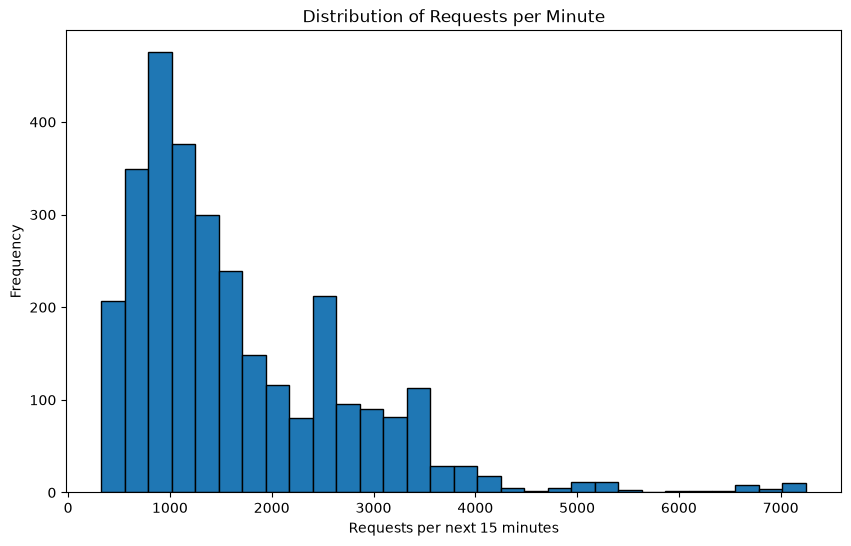

In [28]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
plt.hist(scaling_log['next_15min_requests'], bins=30, edgecolor='black')
plt.xlabel('Requests per next 15 minutes')
plt.ylabel('Frequency')
plt.title('Distribution of Requests per Minute')
plt.show()

In [10]:
## 1.4 Missing Values Analysis
# to avoid missing values affecting the model quality.

print(f"Scaling log DataFrame missing values:\n{scaling_log.isnull().sum()}")

for col in scaling_log.columns:
    missing_percentage = scaling_log[col].isnull().mean() * 100
    if missing_percentage > 0:
     print(f"Column '{col}' has {missing_percentage:.2f}% missing values.")
     #check the rows with missing values and its associated sale event.
    if scaling_log[col].isnull().any():
       missing_rows = scaling_log[scaling_log[col].isnull()]
       print(f"Rows with missing values in column '{col}':\n{missing_rows[['sale_event', col]]}\n")



## Findings : Since not much missings value we are good to drop the rows with missing values.

### Findings 

#Only a small number of missing values were identified in : region , memory utilization and network_mbps and disk_utilization 

# To handle since its very few , we shall verify which sale events its triggering 

        

Scaling log DataFrame missing values:
timestamp               0
sale_event              0
region                  1
active_users            0
requests_per_min        0
orders_per_min          0
cpu_utilization         0
memory_utilization      2
network_mbps            1
disk_utilization        1
response_time_ms        0
current_capacity_rpm    0
next_15min_requests     0
scale_up_required       0
dtype: int64
Column 'region' has 0.03% missing values.
Rows with missing values in column 'region':
    sale_event region
612       Sale    NaN

Column 'memory_utilization' has 0.07% missing values.
Rows with missing values in column 'memory_utilization':
     sale_event  memory_utilization
143      Normal                 NaN
2310       Sale                 NaN

Column 'network_mbps' has 0.03% missing values.
Rows with missing values in column 'network_mbps':
     sale_event  network_mbps
1011     Normal           NaN

Column 'disk_utilization' has 0.03% missing values.
Rows with missing val

## 1.5 Unusual and Extreme Observations

Infrastructure telematry often contains legitatmate spikes caused by real operational events 

Outliers needs to be checked rather than to remove 



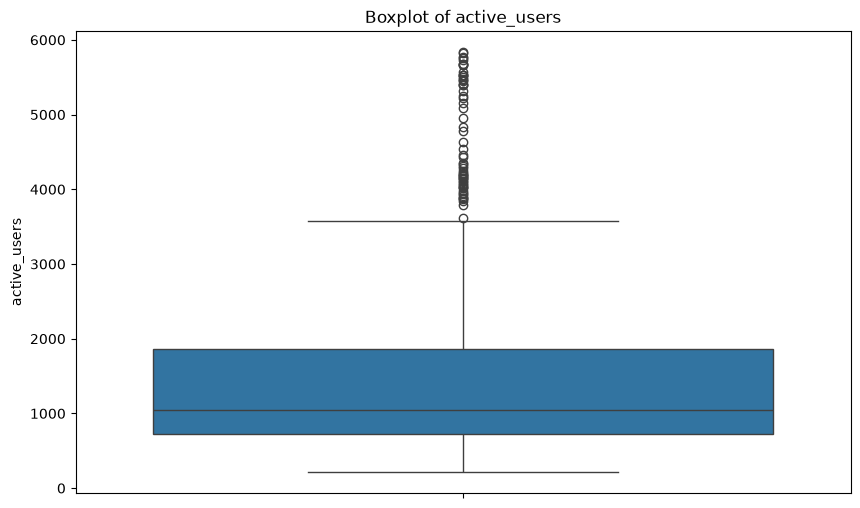

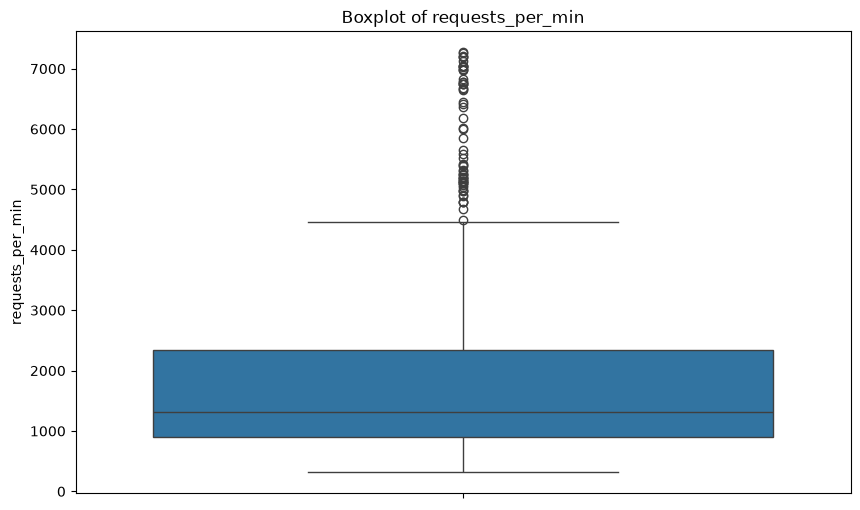

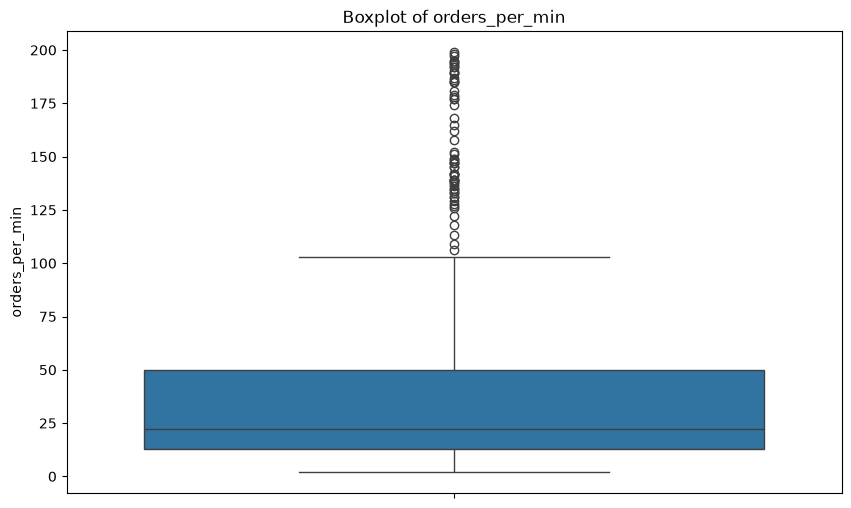

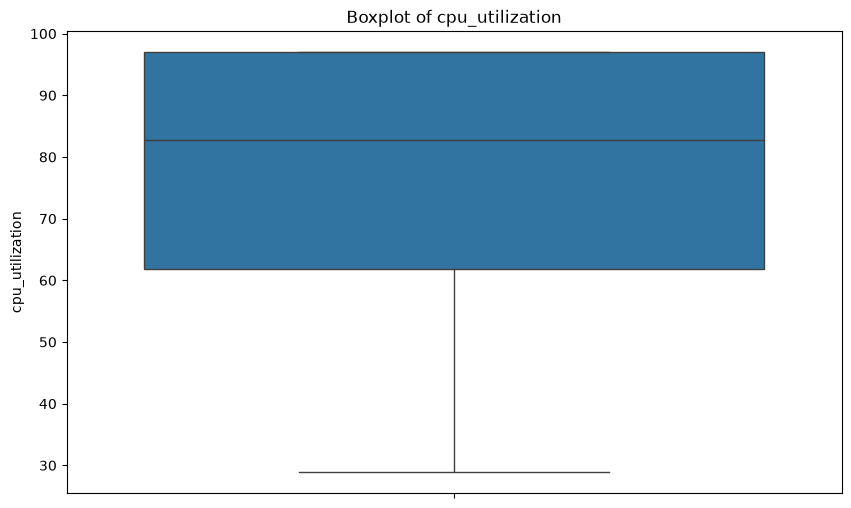

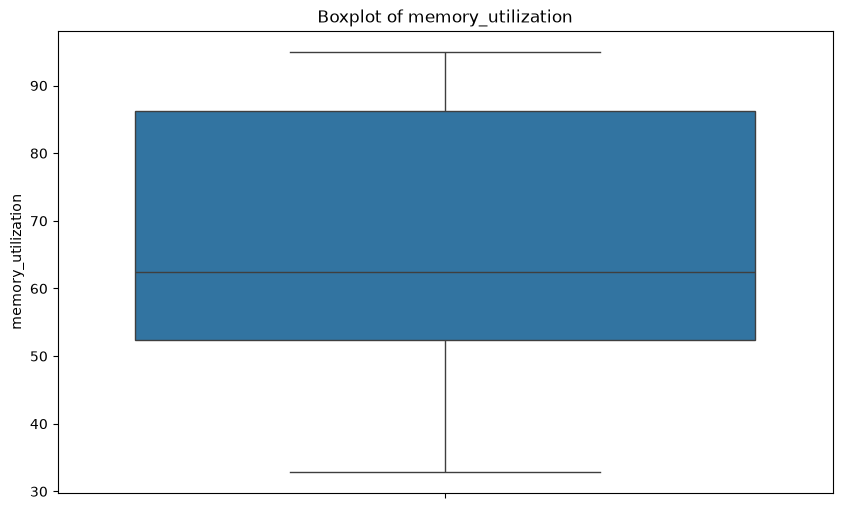

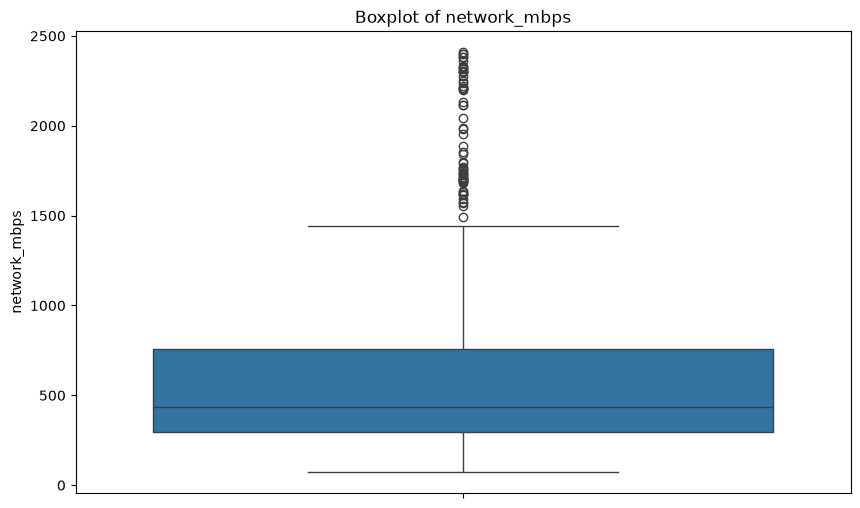

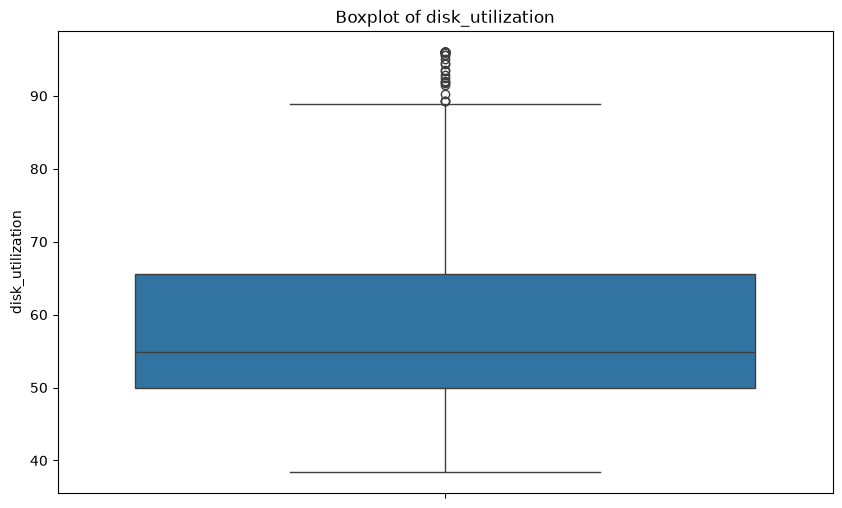

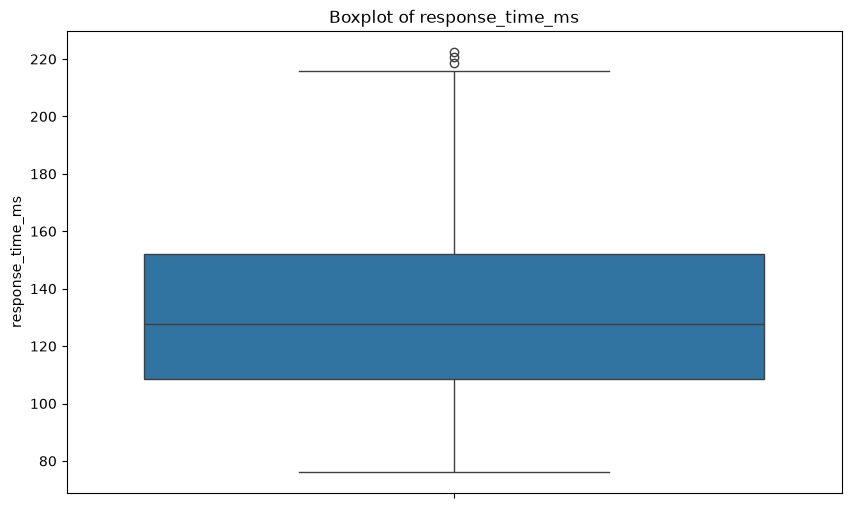

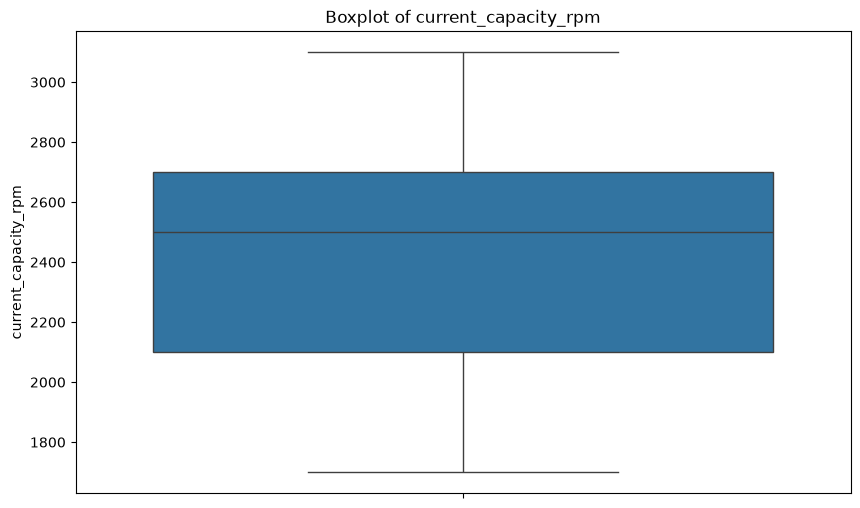

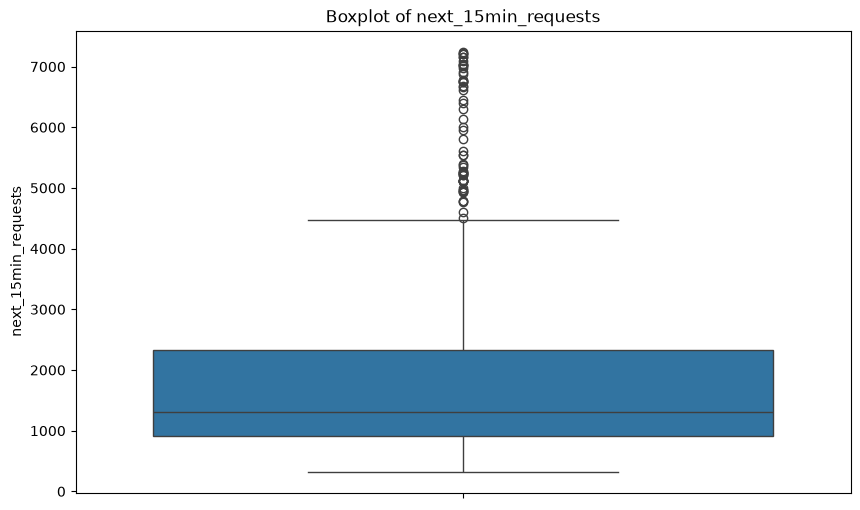

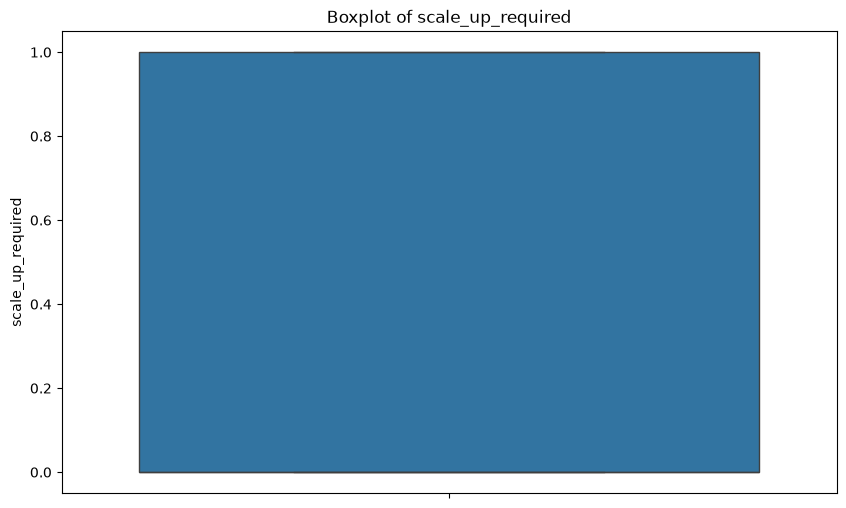

In [30]:
import seaborn as sns

for col in scaling_log.columns:
    if scaling_log[col].dtype in [np.float64, np.int64]:
        plt.figure(figsize=(10, 6))
        sns.boxplot(scaling_log[col])
        plt.title(f'Boxplot of {col}')
        plt.show()
             

In [34]:
# All the EDA completed and data remains intact with no change.


print(f"scaling log dataframe shape {scaling_log.shape}")
print(f"scaling log dataframe info {scaling_log.info()}")

scaling log dataframe shape (3023, 14)
<class 'pandas.DataFrame'>
RangeIndex: 3023 entries, 0 to 3022
Data columns (total 14 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   timestamp             3023 non-null   str    
 1   sale_event            3023 non-null   str    
 2   region                3022 non-null   str    
 3   active_users          3023 non-null   int64  
 4   requests_per_min      3023 non-null   int64  
 5   orders_per_min        3023 non-null   int64  
 6   cpu_utilization       3023 non-null   float64
 7   memory_utilization    3021 non-null   float64
 8   network_mbps          3022 non-null   float64
 9   disk_utilization      3022 non-null   float64
 10  response_time_ms      3023 non-null   float64
 11  current_capacity_rpm  3023 non-null   int64  
 12  next_15min_requests   3023 non-null   int64  
 13  scale_up_required     3023 non-null   int64  
dtypes: float64(5), int64(6), str(3)
memory usage

# Task 2: Data Preparation for ML

## Purpose : Data must be transformed into a machine learning ready dataset 

- create time based features 
- handle missing values
- Encode categorical variables 
- Apply scaling where appropriate 
- seperate target from predictors

The objective is to ensure a clean and reproducible preprocessing pipeline before model developement.


In [68]:
#craeting a copy of df
scaling_log_ml = scaling_log.copy()

#Timestamp information was decomposed into hour of day, day of week and is_weekend features to help the model learn the temporal patterns in the data.

scaling_log_ml['timestamp'] = pd.to_datetime(scaling_log_ml['timestamp'], errors='coerce')

scaling_log_ml['hour_of_day'] = scaling_log_ml['timestamp'].dt.hour
scaling_log_ml['day_of_week'] = scaling_log_ml['timestamp'].dt.dayofweek

scaling_log_ml['is_weekend'] = ( scaling_log_ml['day_of_week'] >= 5).astype(int)


In [69]:
#Missing value treatment

for col in scaling_log_ml.columns:
    if (scaling_log_ml[col].isnull().any()) and (scaling_log_ml[col].dtype in [np.float64, np.int64]):
        
        print(f"Missing values before dropping {col}:\n{scaling_log_ml[col].isnull().sum()}")
        
        scaling_log_ml[col] = scaling_log_ml[col].fillna(scaling_log_ml[col].median())

        print(f"Missing values after filling {col}:\n{scaling_log_ml[col].isnull().sum()}")

Missing values before dropping memory_utilization:
2
Missing values after filling memory_utilization:
0
Missing values before dropping network_mbps:
1
Missing values after filling network_mbps:
0
Missing values before dropping disk_utilization:
1
Missing values after filling disk_utilization:
0


# Why Median to handle missing values

because we had minimal missing values but since its infrastructure metrics and exibits skewed distribution, the median is less sensitive to extreme values than the mean.


# Encode categories 

In [70]:
categorical_cols = [col for col in scaling_log_ml.columns if scaling_log_ml[col].dtypes == 'str']

print(f"Categorical columns:\n{categorical_cols}")

# one hot encoding for categorical variables, avoid multicollinearity by dropping the first category to avoid the dummy variable trap.

scaling_log_ml = pd.get_dummies(scaling_log_ml, columns=categorical_cols, drop_first=True)
for col in categorical_cols:
    for col in categorical_cols:
        encoded_cols = [c for c in scaling_log_ml.columns if c.startswith(f"{col}_")]
        print(f"Encoded columns for '{col}': {encoded_cols}")
        print(scaling_log_ml[encoded_cols].head())

Categorical columns:
['sale_event', 'region']
Encoded columns for 'sale_event': ['sale_event_Normal', 'sale_event_Sale']
   sale_event_Normal  sale_event_Sale
0               True            False
1               True            False
2               True            False
3               True            False
4               True            False
Encoded columns for 'region': ['region_South', 'region_West']
   region_South  region_West
0         False        False
1          True        False
2         False         True
3         False        False
4          True        False
Encoded columns for 'sale_event': ['sale_event_Normal', 'sale_event_Sale']
   sale_event_Normal  sale_event_Sale
0               True            False
1               True            False
2               True            False
3               True            False
4               True            False
Encoded columns for 'region': ['region_South', 'region_West']
   region_South  region_West
0         False      

# Scaling 

LR is sensitive to feature scaling and will use standerdised inputs during model traning

Tree-based algorithms such as Decision Trees, random Forests , K-Means and DBSCAN do not require scaling for predictive performance

so scaling will be applied only where relevant within the modeling pipeline

# Outlier Review 

In [81]:
outliers_summary = []
for col in scaling_log_ml.columns:
    if scaling_log_ml[col].dtypes in [np.float64,np.int64]:
       Q1 = scaling_log_ml[col].quantile(0.25)

       Q3 = scaling_log_ml[col].quantile(0.75)
  
       IQR = Q3 - Q1
       Upper_bound = Q3 + 1.5 * IQR
       Lower_bound = Q1 - 1.5 * IQR

       max = scaling_log_ml[col].max()
       
       outliers = scaling_log_ml[
                       (scaling_log_ml[col] < Lower_bound) |
                       (scaling_log_ml[col] > Upper_bound)
       ].shape[0]
      
       outliers_summary.append((Q1, Q3, IQR,col, outliers,max))

       pd.DataFrame(
           outliers_summary, columns=['Q1', 'Q3', 'IQR', 'Column', 'Outlier Count','max']
       )

print(f"Outlier summary:\n{pd.DataFrame(outliers_summary, columns=['Q1', 'Q3', 'IQR', 'Column', 'Outlier Count','max'])}")

Outlier summary:
         Q1       Q3      IQR                Column  Outlier Count     max
0    722.00  1866.50  1144.50          active_users             62  5836.0
1    907.50  2339.00  1431.50      requests_per_min             62  7272.0
2     13.00    50.00    37.00        orders_per_min             68   199.0
3     61.85    97.00    35.15       cpu_utilization              0    97.0
4     52.45    86.30    33.85    memory_utilization              0    95.0
5    295.30   758.40   463.10          network_mbps             62  2409.7
6     49.90    65.55    15.65      disk_utilization             65    96.0
7    108.40   152.20    43.80      response_time_ms              3   222.4
8   2100.00  2700.00   600.00  current_capacity_rpm              0  3100.0
9    907.50  2333.00  1425.50   next_15min_requests             61  7248.0
10     0.00     1.00     1.00     scale_up_required              0     1.0
11     0.00     1.00     1.00            is_weekend              0     1.0


The requests per min contains observations considerably above the upper quartile 
75th percentle : 2339 req/min
max : 7272 req/min

this dataset includes normal, sale and flash sale periods 

In a e commerce env large spikes in requests users and network throughtput are expected during promotional events 

therefore these observations were reviewed as potential ops surges rather than automatically trated as outliers

# Seperate targets 

In [ ]:
y_reg = scaling_log_ml['next_15min_requests']

y_cls = scaling_log_ml['scale_up_required']

X = scaling_log_ml.drop(columns=['next_15min_requests', 'scale_up_required'])